<a href="https://colab.research.google.com/github/Arti-D/product-analytics-test-task/blob/main/product_analytics_test_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import urllib.request

urllib.request.urlretrieve(
    'https://raw.githubusercontent.com/Arti-D/product-analytics-test-task/main/data/raw.xlsx',
    'raw.xlsx'
)

('raw.xlsx', <http.client.HTTPMessage at 0x7b335b5cab70>)

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

users = pd.read_excel('raw.xlsx')
payments = pd.read_excel('raw.xlsx', sheet_name="Платежи")

## ОПИСАНИЕ ЗАДАЧИ
Тестирование новой формы оплаты ЖКХ с упрощ. заполнением реквизитов.

Воронка:
1. открытие формы
2. введение реквизитов
3. подтверждение платежа
4. успешная оплата

**Гипотеза:** ув доли успешных оплат \
**Ключевая метрика:** конверсия 1->4

Ожидаемый итог: внедрять ли форму?

## ОПИСАНИЕ ДАННЫХ

**Пользователи**
1. user_id - айдишник клиента
2. group - группа экперимента
3. age - возраст
4. city - город
5. device_type - тип устройства

**Платежи**
1. payment_id - айдишка платежа
2. user_id - айлишка клиента
3. group - группа эксперимента
4. step1_opened - время открытия формы
5. step2_entered - время ввода реквизитов
6. step3_confirmed - время подтверждения оплаты
7. step4_success - вермя успешной оплаты

## Проверка данных

In [8]:
print(users.info())
print(payments.info())

#Уникальные значения
print(users["user_id"].nunique()) #1504
print(payments["payment_id"].nunique()) #2661

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success   

Вывод: в пользователях есть пустые значения в колонках группа и город - проверить отдельно \
в платежах - пустые колонки в айди пользователя - клиент не определен

In [9]:
print("Группировка пользователей \n")
print(users.groupby("device_type").size(), '\n')
print(users.groupby("group").size(), '\n')
print(users.groupby("city").size(), '\n')

Группировка пользователей 

device_type
android    777
ios        727
dtype: int64 

group
A    752
B    751
dtype: int64 

city
Москва    595
Регион    514
СПб       394
dtype: int64 



In [10]:
print("Группировка платежей \n")
print(payments.groupby("group").size(), '\n')

Группировка платежей 

group
A    1309
B    1352
dtype: int64 



вывод: по группам все ок - неожиданных группировок нет

In [11]:
# Аномальные и пустые значения:
print("Пользователи \n")
print("Макс возраст: \n", users.loc[users['age'].max() == users['age']], "\n")
print("Мин возраст: \n", users.loc[users['age'].min() == users['age']], "\n")
print("Возраст >= 60: \n", users.loc[users['age'] >= 60], "\n")
print("Возраст до 18: \n", users.loc[users['age'] < 18], "\n")

print("Пустой group \n", users.loc[users['group'].isna()])
print("Пустой city \n", users.loc[users['city'].isna()])

print("Платежи \n")
print("Пустой user_id \n", payments.loc[payments['user_id'].isna()])

Пользователи 

Макс возраст: 
       user_id group  age    city device_type
1502     9003     B  150  Регион         ios 

Мин возраст: 
       user_id group  age city device_type
1501     9002     A   -5  СПб     android 

Возраст >= 60: 
       user_id group  age    city device_type
68       1069     A   60  Регион         ios
817      1818     B   60  Регион         ios
1502     9003     B  150  Регион         ios 

Возраст до 18: 
       user_id group  age city device_type
1501     9002     A   -5  СПб     android 

Пустой group 
       user_id group  age    city device_type
1500     9001   NaN   25  Москва         ios
Пустой city 
       user_id group  age city device_type
1503     9004     A   30  NaN     android
Платежи 

Пустой user_id 
       payment_id  user_id group        step1_opened step2_entered  \
2660       99003      NaN     A 2024-04-12 09:15:00           NaT   

     step3_confirmed step4_success  
2660             NaT           NaT  


Вывод: есть 2 аномальных значения по возрасту 150 и -5: возможно ошибка в данных пользователя (хотя странно что они вообще есть, у нас что ли валидации возраста нет?? - уточнить у бэка и фронта) \

❗есть 1 платеж от неизвестного клиента, не проставился user_id


In [12]:
# Число попыток на клиента
pay_attempts = payments.groupby('user_id').size()
max_pay_attempts = pay_attempts.max()
top_user_ids = pay_attempts[pay_attempts == max_pay_attempts]
print(top_user_ids)

print(pay_attempts.head(-20))

user_id
1036.0    4
1045.0    4
1109.0    4
1132.0    4
1154.0    4
         ..
2460.0    4
2461.0    4
2467.0    4
2473.0    4
2490.0    4
Length: 80, dtype: int64
user_id
1001.0    1
1002.0    1
1003.0    1
1004.0    3
1005.0    2
         ..
2477.0    1
2478.0    1
2479.0    1
2480.0    3
2481.0    1
Length: 1481, dtype: int64


## ПОДГОТОВКА ДАННЫХ

In [13]:
# Исключаем из таблицы payments пользователя с неизвестным user_id
pmts = payments.dropna(subset=['user_id']).copy()
pmts['user_id'] = pmts['user_id'].astype('int64')
print(pmts.info())

<class 'pandas.core.frame.DataFrame'>
Index: 2660 entries, 0 to 2659
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2660 non-null   int64         
 1   user_id          2660 non-null   int64         
 2   group            2660 non-null   object        
 3   step1_opened     2660 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), int64(2), object(1)
memory usage: 166.2+ KB
None


In [14]:
# Проверка пользователя без группы
users_without_group = users.loc[users['group'].isna(), 'user_id'].tolist()
print(users_without_group)

payments_of_users_without_group = payments[payments['user_id'].isin(users_without_group)]
print(payments_of_users_without_group)

[9001]
Empty DataFrame
Columns: [payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success]
Index: []


вывод: пользователь без группы не учавствует в платежах так что тут тоже все оки

# ПРОВЕРКА ДАТ

попадание на форму 100% пустых колонок нет, последовательность шагов везде ок

In [15]:
# последовательность шагов
mask1 = (
    pmts["step2_entered"].notna()
    & pmts["step1_opened"].isna()
)

mask2 = (
    pmts['step3_confirmed'].notna()
    & pmts["step2_entered"].isna()
)
mask3 = (
    pmts['step4_success'].notna()
    & pmts['step3_confirmed'].isna()
)
mask4 = (pmts['step1_opened'].isna())

print(pmts.loc[mask1])
print(pmts.loc[mask2])
print(pmts.loc[mask3])
print(pmts.loc[mask4])

Empty DataFrame
Columns: [payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success]
Index: []
Empty DataFrame
Columns: [payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success]
Index: []
Empty DataFrame
Columns: [payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success]
Index: []
Empty DataFrame
Columns: [payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success]
Index: []


In [16]:
# последовательность шагов
timemask1 = (
    pmts["step1_opened"].notna()
    & pmts["step2_entered"].notna()
    & (pmts["step2_entered"] < pmts["step1_opened"])
)
timemask2 = (
    pmts["step3_confirmed"].notna()
    & pmts["step2_entered"].notna()
    & (pmts["step3_confirmed"] < pmts["step2_entered"])
)
timemask3 = (
    pmts["step3_confirmed"].notna()
    & pmts["step4_success"].notna()
    & (pmts["step4_success"] < pmts["step3_confirmed"])
)

print(pmts.loc[timemask1])
print(pmts.loc[timemask2])
print(pmts.loc[timemask3])

Empty DataFrame
Columns: [payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success]
Index: []
Empty DataFrame
Columns: [payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success]
Index: []
Empty DataFrame
Columns: [payment_id, user_id, group, step1_opened, step2_entered, step3_confirmed, step4_success]
Index: []


In [17]:
#нет ли записей вышедших за время теста
period = (
    (pmts["step1_opened"] < pd.Timestamp("2024-04-01"))
    | (pmts["step1_opened"] >= pd.Timestamp("2024-05-01"))
)

# тут еще можно глянуть если вечером 30 апреля открыли форму, а завершили оплату 1 мая,
# но я считаю что эт норм

pmts.loc[period] # - 0

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


# объединение таблиц

In [18]:
data = pmts.merge(users, on='user_id', how='left')
#проверим что норм смержили:
#совпадают ли группы
print(data.loc[data['group_x'] != data['group_y'], 'user_id'])
#есть ли клиенты где нет групп
print(data[data['group_x'].isna() | data['group_y'].isna()]) #тут пусто

print(data.loc[data['user_id'] == 1010])


2659    1010
Name: user_id, dtype: int64
Empty DataFrame
Columns: [payment_id, user_id, group_x, step1_opened, step2_entered, step3_confirmed, step4_success, group_y, age, city, device_type]
Index: []
      payment_id  user_id group_x        step1_opened       step2_entered  \
14          5015     1010       A 2024-04-27 13:26:00                 NaT   
2659       99002     1010       B 2024-04-08 14:20:00 2024-04-08 14:23:00   

         step3_confirmed       step4_success group_y  age    city device_type  
14                   NaT                 NaT       A   26  Москва     android  
2659 2024-04-08 14:28:00 2024-04-08 14:29:00       A   26  Москва     android  


1 платеж не совпадают группы (user_id=1010) - у клиента 2 платежа, в первом случае группы AA во втором AB - странно надо проверить, возможно убрать из анализа, возможно принять группу за A

In [19]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2660 entries, 0 to 2659
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2660 non-null   int64         
 1   user_id          2660 non-null   int64         
 2   group_x          2660 non-null   object        
 3   step1_opened     2660 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
 7   group_y          2660 non-null   object        
 8   age              2660 non-null   int64         
 9   city             2659 non-null   object        
 10  device_type      2660 non-null   object        
dtypes: datetime64[ns](4), int64(3), object(4)
memory usage: 228.7+ KB


# Финальная обработка данных и промеж итоги

1. Выкинули из выборки платежей платеж без user_id
2. Смержили таблицы, уникальных значений платежей не изменилось, нулевых строк нет
3. У одного из пользователей не указан город
4. Выкинули из выборки операции для пользователя где не совпадают группы в 1й из опрераций (user_id=1010)
5. Возраста 150 и -5 оказались у пользователей без платежей, так что до анализа они не дошли. Замену на nan оставила на всякий случай.
6. Всего три пользователя без платежей и один с конфликтом групп: 1504 -> 1500 пользователей.


In [20]:
data.loc[(data['age'] < 0) | (data['age'] > 90), 'age'] = np.nan
data = data[~(data['user_id'] == 1010)].copy()

print('Уникальных платежей', data['payment_id'].nunique())
print('Уникальных клиентов', data['user_id'].nunique())

Уникальных платежей 2658
Уникальных клиентов 1500


In [21]:
# Состав групп по уникальным пользователям
profile = (
    data[['user_id', 'group_x', 'age', 'device_type', 'city']]
    .drop_duplicates(subset='user_id')
    .rename(columns={'group_x': 'group'})
)

print('Число пользователей:')
display(
    profile.groupby('group')['user_id']
    .nunique()
    .rename('users')
    .to_frame()
)

# Возраст: пропуски после очистки не включаются в среднее и медиану
age_summary = profile.groupby('group')['age'].agg(
    users='size',
    known_age='count',
    mean_age='mean',
    median_age='median',
    std_age='std',
)

age_summary['missing_age'] = (
    age_summary['users'] - age_summary['known_age']
)

print('Сравнение возраста:')
display(age_summary.round(2))


# Устройства и города: количество и доля внутри каждой группы
def compare_categories(df, column):
    counts = pd.crosstab(
        df[column].fillna('Не указан'),
        df['group']
    ).reindex(columns=['A', 'B'], fill_value=0)

    shares = counts.div(counts.sum(axis=0), axis=1) * 100

    return pd.DataFrame({
        'A: пользователей': counts['A'],
        'A: доля, %': shares['A'].round(2),
        'B: пользователей': counts['B'],
        'B: доля, %': shares['B'].round(2),
        'Разница B − A, п.п.': (
            shares['B'] - shares['A']
        ).round(2),
    })


print('Сравнение устройств:')
display(compare_categories(profile, 'device_type'))

print('Сравнение городов:')
display(compare_categories(profile, 'city'))

Число пользователей:


,users
group,
A,750
B,750


Сравнение возраста:


,users,known_age,mean_age,median_age,std_age,missing_age
group,,,,,,
A,750,750,32.75,32.0,7.82,0
B,750,750,32.65,33.0,7.78,0


Сравнение устройств:


,A: пользователей,"A: доля, %",B: пользователей,"B: доля, %","Разница B − A, п.п."
device_type,,,,,
android,406,54.13,369,49.2,-4.93
ios,344,45.87,381,50.8,4.93


Сравнение городов:


,A: пользователей,"A: доля, %",B: пользователей,"B: доля, %","Разница B − A, п.п."
city,,,,,
Москва,287,38.27,306,40.80,2.53
Не указан,1,0.13,0,0.00,-0.13
Регион,268,35.73,245,32.67,-3.07
СПб,194,25.87,199,26.53,0.67


# Сводные показатели

In [22]:
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
step_labels = ['Открыли форму', 'Ввели реквизиты', 'Подтвердили', 'Успешная оплата']

def funnel(df, group):
    counts = [df[s].notna().sum() for s in steps]
    return {
        'group': group,
        'total': len(df),
        **{f'step{i+1}': c for i, c in enumerate(counts)},
        'conv_1_total': counts[0] / len(df) if len(df) else None,
        'conv_2_1': counts[1] / counts[0] if counts[0] else None,
        'conv_3_1': counts[2] / counts[0] if counts[0] else None,
        'conv_4_1': counts[3] / counts[0] if counts[0] else None,
        'conv_3_2': counts[2] / counts[1] if counts[1] else None,
        'conv_4_3': counts[3] / counts[2] if counts[2] else None,
    }

funnel_df = pd.DataFrame([funnel(data.loc[data['group_x'] == g], g) for g in ['A', 'B']])
print(funnel_df)

  group  total  step1  step2  step3  step4  conv_1_total  conv_2_1  conv_3_1  \
0     A   1307   1307   1061    758    651           1.0  0.811783  0.579954   
1     B   1351   1351   1194    960    870           1.0  0.883790  0.710585   

   conv_4_1  conv_3_2  conv_4_3  
0  0.498087   0.71442  0.858839  
1  0.643967   0.80402  0.906250  


## Графики

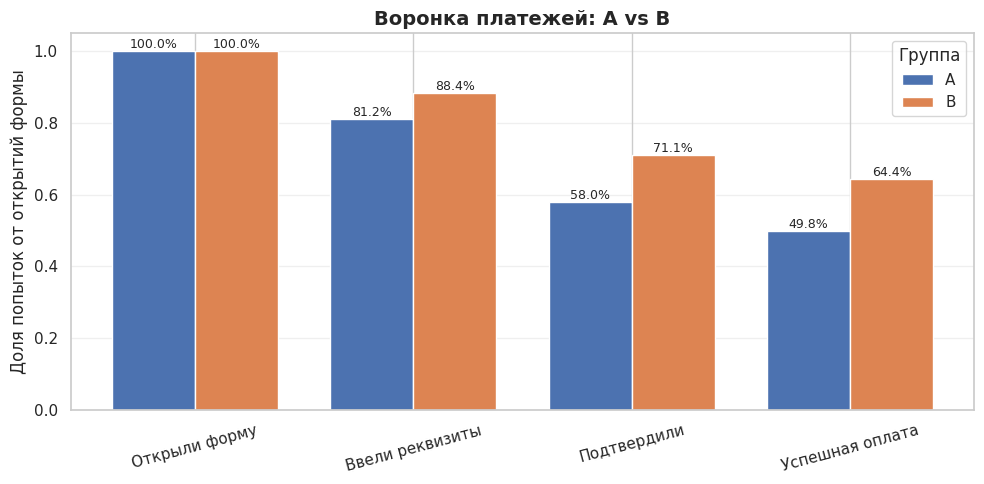

In [23]:
conv_steps = ['conv_1_total', 'conv_2_1', 'conv_3_1', 'conv_4_1']
labels = ['Открыли форму', 'Ввели реквизиты', 'Подтвердили', 'Успешная оплата']

x = np.arange(len(conv_steps))
w = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, funnel_df.loc[0, conv_steps], w, label='A')
ax.bar(x + w/2, funnel_df.loc[1, conv_steps], w, label='B')

ax.set_xticks(x, labels, rotation=15)
ax.set_ylabel('Доля попыток от открытий формы')
ax.set_title('Воронка платежей: A vs B', fontsize=14, fontweight='bold')
ax.legend(title='Группа')
ax.grid(axis='y', alpha=0.3)

# подписи значений над столбиками — очень помогает читать
for i, (a, b) in enumerate(zip(funnel_df.loc[0, conv_steps], funnel_df.loc[1, conv_steps])):
    ax.text(i - w/2, a, f'{a:.1%}', ha='center', va='bottom', fontsize=9)
    ax.text(i + w/2, b, f'{b:.1%}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Бутстрап

In [24]:
def pmts_group_by_users(df):
    result = (
        df.groupby('user_id', as_index=False)
          .agg(
              group      = ('group_x', 'first'),
              attempts   = ('step1_opened', 'size'),
              successful = ('step4_success', 'count'),
          )
    )
    result['successful_rate'] = result['successful'] / result['attempts']
    return result


data_a = data.loc[data['group_x'] == 'A']
data_b = data.loc[data['group_x'] == 'B']

pmts_group_by_users_A = pmts_group_by_users(data_a)
pmts_group_by_users_B = pmts_group_by_users(data_b)
pmts_group_by_users_A
pmts_group_by_users_B



,user_id,group,attempts,successful,successful_rate
0,1751,B,1,0,0.000000
1,1752,B,3,1,0.333333
2,1753,B,1,1,1.000000
3,1754,B,2,1,0.500000
4,1755,B,1,1,1.000000
...,...,...,...,...,...
745,2496,B,1,1,1.000000
746,2497,B,1,0,0.000000
747,2498,B,1,1,1.000000
748,2499,B,3,3,1.000000


In [25]:
def bootstrap_rate(df, n_boot=10_000, ci=95, random_state=42):
    rng = np.random.default_rng(random_state)
    n = len(df)

    attempts = df['attempts'].to_numpy()
    successful = df['successful'].to_numpy()

    rates = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        rates[i] = successful[idx].sum() / attempts[idx].sum()

    point = successful.sum() / attempts.sum()
    lower = np.percentile(rates, (100 - ci) / 2)
    upper = np.percentile(rates, 100 - (100 - ci) / 2)
    return point, lower, upper

rate_a, lo_a, hi_a = bootstrap_rate(pmts_group_by_users_A)
rate_b, lo_b, hi_b = bootstrap_rate(pmts_group_by_users_B)

print(f"A: rate = {rate_a:.4f}, 95% CI = [{lo_a:.4f}, {hi_a:.4f}]")
print(f"B: rate = {rate_b:.4f}, 95% CI = [{lo_b:.4f}, {hi_b:.4f}]")


def bootstrap_diff(df_a, df_b, n_boot=10_000, ci=95, random_state=42):
    rng = np.random.default_rng(random_state)

    def resample_rate(df):
        n = len(df)
        idx = rng.integers(0, n, size=n)
        att = df['attempts'].to_numpy()[idx].sum()
        suc = df['successful'].to_numpy()[idx].sum()
        return suc / att

    diffs = np.empty(n_boot)
    for i in range(n_boot):
        rate_a = resample_rate(df_a)
        rate_b = resample_rate(df_b)
        diffs[i] = rate_b - rate_a

    point = (df_b['successful'].sum() / df_b['attempts'].sum()
             - df_a['successful'].sum() / df_a['attempts'].sum())
    lower = np.percentile(diffs, (100 - ci) / 2)
    upper = np.percentile(diffs, 100 - (100 - ci) / 2)
    p_value = 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
    return point, lower, upper, p_value

diff, lo_diff, hi_diff, p_val = bootstrap_diff(pmts_group_by_users_A, pmts_group_by_users_B)
print(f"Разница B - A: {diff:.4f}, 95% CI = [{lo_diff:.4f}, {hi_diff:.4f}]")

A: rate = 0.4981, 95% CI = [0.4710, 0.5253]
B: rate = 0.6440, 95% CI = [0.6177, 0.6692]
Разница B - A: 0.1459, 95% CI = [0.1086, 0.1832]


## Дополнительные проверки

### Пользователи без платежей и дубли

In [26]:
print('Пользователи без платежей:')
print(users.loc[~users['user_id'].isin(pmts['user_id'])])

print('Дубли user_id:', users['user_id'].duplicated().sum())
print('Дубли payment_id:', payments['payment_id'].duplicated().sum())
print('Одинаковые попытки с разными payment_id:', pmts.duplicated(
    subset=['user_id', 'step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
).sum())

Пользователи без платежей:
      user_id group  age    city device_type
1500     9001   NaN   25  Москва         ios
1501     9002     A   -5     СПб     android
1502     9003     B  150  Регион         ios
Дубли user_id: 0
Дубли payment_id: 0
Одинаковые попытки с разными payment_id: 0


### SRM

Проверка численности исходных групп, если сплит планировался 50/50.

In [27]:
from scipy.stats import chisquare

group_counts = users.groupby('group').size()
chi2, p_srm = chisquare(group_counts)
print(group_counts)
print(f'SRM: p = {p_srm:.3f}')

group
A    752
B    751
dtype: int64
SRM: p = 0.979


### Android и iOS

In [28]:
platforms = data.groupby(['device_type', 'group_x']).agg(
    attempts=('payment_id', 'size'),
    successful=('step4_success', 'count')
)
platforms['conv'] = platforms['successful'] / platforms['attempts']
print(platforms)

platform_conv = platforms['conv'].unstack('group_x')
platform_conv['diff_pp'] = (platform_conv['B'] - platform_conv['A']) * 100
print(platform_conv)

# Приведем обе группы к общим долям устройств среди всех попыток
device_weights = data.groupby('device_type').size() / len(data)
conv_a = (platform_conv['A'] * device_weights).sum()
conv_b = (platform_conv['B'] * device_weights).sum()
print(f'Разница при одинаковом составе устройств: {(conv_b - conv_a) * 100:.2f} п.п.')

                     attempts  successful      conv
device_type group_x                                
android     A             713         349  0.489481
            B             666         425  0.638138
ios         A             594         302  0.508418
            B             685         445  0.649635
group_x             A         B    diff_pp
device_type                               
android      0.489481  0.638138  14.865707
ios          0.508418  0.649635  14.121753
Разница при одинаковом составе устройств: 14.51 п.п.


### Хотя бы одна успешная оплата

Тут считаем уже пользователей, а не попытки.

In [29]:
users_success = data.groupby(['group_x', 'user_id'])['step4_success'].count().reset_index()
users_success['has_success'] = users_success['step4_success'] > 0

user_conv = users_success.groupby('group_x')['has_success'].agg(['sum', 'count', 'mean'])
print(user_conv)
print(f"Разница: {(user_conv.loc['B', 'mean'] - user_conv.loc['A', 'mean']) * 100:.2f} п.п.")

         sum  count      mean
group_x                      
A        493    750  0.657333
B        603    750  0.804000
Разница: 14.67 п.п.


### Первые попытки

In [30]:
first_payments = data.sort_values(['step1_opened', 'payment_id']).drop_duplicates('user_id')
first_funnel = pd.DataFrame([
    funnel(first_payments.loc[first_payments['group_x'] == g], g) for g in ['A', 'B']
])
print(first_funnel[['group', 'step1', 'step4', 'conv_4_1']])
print(f"Разница: {(first_funnel.loc[1, 'conv_4_1'] - first_funnel.loc[0, 'conv_4_1']) * 100:.2f} п.п.")

  group  step1  step4  conv_4_1
0     A    750    381  0.508000
1     B    750    493  0.657333
Разница: 14.93 п.п.


### По неделям

1–7, 8–14, 15–21, 22–28 апреля; пятая строка — только 29–30 апреля.

In [31]:
weekly = data.copy()
weekly['week'] = (weekly['step1_opened'] - pd.Timestamp('2024-04-01')).dt.days // 7 + 1

weekly_conv = weekly.groupby(['week', 'group_x']).agg(
    attempts=('payment_id', 'size'),
    successful=('step4_success', 'count')
)
weekly_conv['conv'] = weekly_conv['successful'] / weekly_conv['attempts']
print(weekly_conv)

weekly_diff = weekly_conv['conv'].unstack('group_x')
weekly_diff['diff_pp'] = (weekly_diff['B'] - weekly_diff['A']) * 100
print(weekly_diff)

              attempts  successful      conv
week group_x                                
1    A             306         156  0.509804
     B             350         232  0.662857
2    A             298         156  0.523490
     B             329         217  0.659574
3    A             300         144  0.480000
     B             284         177  0.623239
4    A             314         150  0.477707
     B             288         183  0.635417
5    A              89          45  0.505618
     B             100          61  0.610000
group_x         A         B    diff_pp
week                                  
1        0.509804  0.662857  15.305322
2        0.523490  0.659574  13.608454
3        0.480000  0.623239  14.323944
4        0.477707  0.635417  15.770966
5        0.505618  0.610000  10.438202


### Время прохождения

До реквизитов — среди дошедших до ввода, до оплаты — среди успешных попыток.

In [32]:
time_data = data.copy()
time_data['time_1_2'] = (time_data['step2_entered'] - time_data['step1_opened']).dt.total_seconds() / 60
time_data['time_1_4'] = (time_data['step4_success'] - time_data['step1_opened']).dt.total_seconds() / 60
print(time_data.groupby('group_x')[['time_1_2', 'time_1_4']].median())

         time_1_2  time_1_4
group_x                    
A             1.0      12.0
B             1.0      12.0


## Итоги

Результаты работы и выводы представлены в отчете.

По дополнительным срезам здесь смотрим на значения, отдельно значимость не проверяли. Основной вывод по доверительному интервалу разницы из бутстрапа.